In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from src.session_loader import Session

2024-12-03 15:39:38.483230: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-12-03 15:39:38.483287: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-12-03 15:39:38.483294: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
reg_matrix = np.load(r'processed-data/registration/Oct_2024_synthetic/1001_registered_ids.npy')
indexing = np.load(r'processed-data/registration/Oct_2024_synthetic/1001_session_indexing.npy', allow_pickle=True).item()
print(reg_matrix.shape, indexing)

(250, 6) {'HBTD1': 0, 'HBTD2': 1, 'HBTD3': 2, 'HBTD4': 3, 'HBTD5': 4, 'HBTD6': 5}


In [3]:
session_file = pd.read_csv('data/SESSION_FILE_insilico_2024-11-26_14-25-32.csv')
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Miniscope video,Criteria,Sex,Final Outcome,...,Maximum Shift,True Number,ManualAnnotationSide,Normalized components,Num of Liberation cells,% of Liberation cells,Liberation Associated Cells Metadata Path,Num of Random cells,% of Random cells,Random Associated Cells Metadata Path
0,False,HBTD1,Oct_2024_synthetic,05.11.2024,1001,1001-0000,05.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
1,False,HBTD2,Oct_2024_synthetic,06.11.2024,1001,1001-0000,06.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.38,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
2,False,HBTD3,Oct_2024_synthetic,07.11.2024,1001,1001-0000,07.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.00,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
3,False,HBTD4,Oct_2024_synthetic,08.11.2024,1001,1001-0000,08.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.14,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
4,False,HBTD5,Oct_2024_synthetic,09.11.2024,1001,1001-0000,09.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...


In [4]:
session_file = session_file[session_file['Mouse'] == 1001]
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Miniscope video,Criteria,Sex,Final Outcome,...,Maximum Shift,True Number,ManualAnnotationSide,Normalized components,Num of Liberation cells,% of Liberation cells,Liberation Associated Cells Metadata Path,Num of Random cells,% of Random cells,Random Associated Cells Metadata Path
0,False,HBTD1,Oct_2024_synthetic,05.11.2024,1001,1001-0000,05.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
1,False,HBTD2,Oct_2024_synthetic,06.11.2024,1001,1001-0000,06.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.38,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
2,False,HBTD3,Oct_2024_synthetic,07.11.2024,1001,1001-0000,07.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.00,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
3,False,HBTD4,Oct_2024_synthetic,08.11.2024,1001,1001-0000,08.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.14,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
4,False,HBTD5,Oct_2024_synthetic,09.11.2024,1001,1001-0000,09.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...


In [5]:
pos_dic = {}

for i, row in session_file.iterrows():
    session = Session(row)
    positions = session.extract_neuron_positions(session.get_neuron_labels())
    pos_dic[session.session] = positions

pos_dic

{'HBTD1': array([[ 59., 336.],
        [103., 283.],
        [123., 315.],
        [106., 331.],
        [100., 367.],
        [110., 401.],
        [123., 413.],
        [142., 238.],
        [138., 324.],
        [147., 362.],
        [145., 387.],
        [148., 543.],
        [169.,  99.],
        [182., 126.],
        [183., 240.],
        [180., 270.],
        [174., 260.],
        [168., 292.],
        [168., 343.],
        [176., 375.],
        [173., 401.],
        [158., 417.],
        [165., 450.],
        [156., 483.],
        [178., 483.],
        [168., 487.],
        [203., 105.],
        [196., 259.],
        [197., 247.],
        [206., 269.],
        [190., 287.],
        [192., 296.],
        [202., 277.],
        [199., 324.],
        [189., 315.],
        [204., 311.],
        [211., 315.],
        [208., 393.],
        [201., 367.],
        [195., 389.],
        [194., 398.],
        [193., 415.],
        [206., 432.],
        [188., 447.],
        [210., 468.],
 

In [7]:
import numpy as np
from collections import defaultdict
from scipy.spatial.distance import pdist
from typing import Dict, List, Tuple
import pandas as pd

def compute_distances(assignments: np.ndarray, 
                       indexing: Dict[str, int], 
                       positions: Dict[str, np.ndarray]) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute distances between registered and non-registered neurons.

    Parameters
    ----------
    assignments : np.ndarray
        Array of assigned neuron IDs across sessions.
    indexing : Dict[str, int]
        Dictionary mapping session keys to column indices in assignments.
    positions : Dict[str, np.ndarray]
        Dictionary mapping session keys to arrays of neuron positions.

    Returns
    -------
    Tuple[np.ndarray, np.ndarray]
        Two numpy arrays containing equal number of pairwise distances: 
        registered_distances and non_registered_distances.
    """
    registered_distances: List[float] = []
    non_registered_distances: List[float] = []

    # Calculate distances for registered neurons
    for i in range(assignments.shape[0]):
        neuron_positions = [positions[k][int(assignments[i, j]), :] for k, j in indexing.items() if not np.isnan(assignments[i, j])]
        if len(neuron_positions) > 1:
            dists = pdist(neuron_positions)
            registered_distances.extend(dists)

    # Calculate distances for all neurons within each session
    for s in positions.values():
        dists = pdist(s)
        non_registered_distances.extend(dists)

    # Ensure both lists have the same number of samples
    min_length = min(len(registered_distances), len(non_registered_distances))
    return np.array(registered_distances[:min_length]), np.array(non_registered_distances[:min_length])

/home/aagafono/projects/helping-behaviour-calcium-imaging/src/plotting.py:842: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.swarmplot(
/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 22758.
  res = hypotest_fun_out(*samples, **kwds)


<Axes: xlabel='Group', ylabel='Distance'>

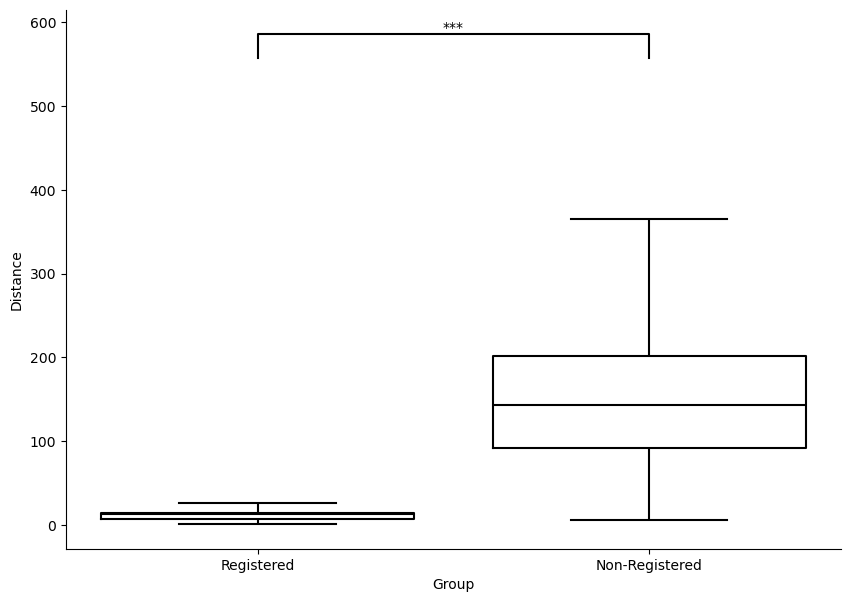

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_boxplots(registered_distances, non_registered_distances, ax=ax, labels=['Registered', 'Non-Registered'], ylabel='Distance')